In [ ]:
import os

# Select the backend before importing PyRITE, then restart to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

with mo.status.spinner(title="Preparing PyRITE reference tables"):
    _ = pyrite.fetch_tables()

tables_ready = True

# Persisted parameter studies

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/18-persisted-parameter-studies.py)

A single `simulate()` returns one in-memory `Result`. A **`Sweep`** expands
a Cartesian product of scenes into cases that a checkpoint-aware runner
can save, reload and resume. Here we vary beam energy and HOPG thickness
(four inexpensive CPU cases), inspect the persisted results, and run the
same sweep a second time without repeating completed transport.

We use a temporary workspace so rerunning this example cannot mix with
production checkpoints. Replace it with a persistent directory to resume
the study after restarting Python.

In [ ]:
from tempfile import TemporaryDirectory

from pyrite import Scene, Sweep
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector
from pyrite.execution import run_sweep
from pyrite.geometry import Footprint, Slab
from pyrite.results import Settings, records, select_results, summary_table, sweep_values
from pyrite.storage import checkpoint_manifest, load_checkpoint
from pyrite.units import ureg

energies_keV = np.array([30.0, 40.0])
thicknesses_nm = np.array([50.0, 100.0])
scene = Scene(
    Beam(
        kinetic_energy=30 * ureg.keV,
        transverse=PointSpot(),
        longitudinal=PointBunch(),
    ),
    Slab(
        "hopg",
        thickness=50 * ureg.nm,
        tilt=30 * ureg.degree,
        footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
    ),
    Detector(observation_angle=135 * ureg.degree),
)
sweep = Sweep(
    base=scene,
    axes={
        "beam.kinetic_energy": tuple(float(e) * ureg.keV for e in energies_keV),
        "target.thickness": tuple(float(t) * ureg.nm for t in thicknesses_nm),
    },
)
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=64, brem_electrons=64),
    cxr_reflections=CxrReflections(n_families=1),
    seed=101,
)
physics = Physics(
    brem_source="none",
    inelastic_model="continuous",
    radiative_model="uncoupled",
)
cases = sweep.cases(numerics=numerics, physics=physics)
assert len(cases) == 4
assert len({(case["name"], case["E0_keV"]) for case in cases}) == 4

In [ ]:
assert tables_ready
workspace = TemporaryDirectory(prefix="pyrite-persisted-sweep-")
first_store = {}
with mo.status.spinner(title="Running and checkpointing four cases"):
    completed = run_sweep(
        cases,
        first_store,
        checkpoint_dir=workspace.name,
        resume=True,
        max_workers=0,
        progress=False,
    )
assert completed
assert sum(map(len, first_store.values())) == len(cases)

4 of 4 cases to run (0 cached)
4 cases in 1 s
checkpoint: saving completed material


## Reload and resume

Each case is identified by its saved `name` and electron energy; the
lowering step also assigns distinct deterministic seeds (101–104).
Finished cases are written as components beneath `hopg/` in the temporary
checkpoint root. `load_checkpoint` reconstructs the nested
`{name: {electron_energy_keV: record}}` store.

The second run starts with an **empty** in-memory dictionary. Its progress
callback must report all four cases cached and zero new cases. This tests
disk-backed resume rather than merely reusing the first Python dictionary.

In [ ]:
saved_store = load_checkpoint("hopg", checkpoint_dir=workspace.name)
assert len(records(saved_store)) == len(cases)

# The loaded arrays are exactly the ones produced in the first execution.
for _case in cases:
    _key = _case["name"]
    _energy = _case["E0_keV"]
    for _field in ("E_grid", "spec", "brem"):
        np.testing.assert_array_equal(
            first_store[_key][_energy][_field],
            saved_store[_key][_energy][_field],
        )

resumed_store = {}
resume_events = []


def _record_progress(new, total, cached):
    resume_events.append((new, total, cached))


resumed = run_sweep(
    cases,
    resumed_store,
    checkpoint_dir=workspace.name,
    resume=True,
    max_workers=0,
    progress=False,
    on_progress=_record_progress,
)
assert resumed and resume_events
assert resume_events[-1] == (0, len(cases), len(cases))
for _case in cases:
    _key = _case["name"]
    _energy = _case["E0_keV"]
    np.testing.assert_array_equal(
        saved_store[_key][_energy]["spec"],
        resumed_store[_key][_energy]["spec"],
    )

loaded 4 hopg records from /tmp/pyrite-persisted-sweep-h64fcmyk/hopg
checkpoint: loading /tmp/pyrite-persisted-sweep-h64fcmyk/hopg
checkpoint: loaded in 0.095 s
resumed 4 hopg cases from /tmp/pyrite-persisted-sweep-h64fcmyk/hopg
0 of 4 cases to run (4 cached)
0 cases in 0 s


In [ ]:
manifest = checkpoint_manifest("hopg", checkpoint_dir=workspace.name)
assert manifest is not None
assert manifest["n_records"] == len(cases)
assert manifest["completed_case_set"]["count"] == len(cases)
seeds = sorted({int(case["seed"]) for case in cases})
assert seeds == [101, 102, 103, 104]
mo.md(
    f"**Recorded case seeds:** {seeds}. "
    "**Completed case-set SHA-256:** "
    f"`{manifest['completed_case_set']['sha256']}`. "
    "This hash verifies the set of stored case labels and energies; "
    "it is *not* a physics-content hash. Keep the inputs and table versions "
    "with your saved checkpoint for a reproducible study."
)

**Recorded case seeds:** [101, 102, 103, 104]. **Completed case-set SHA-256:** `a6112919f53d54679987d98e7a0b2e4d06067cbb5f15b531d0756b9825cd5465`. This hash verifies the set of stored case labels and energies; it is *not* a physics-content hash. Keep the inputs and table versions with your saved checkpoint for a reproducible study.

In [ ]:
available = sweep_values(saved_store, fields=("E0_keV", "thickness_ang"))
selected = select_results(saved_store, E0_keV=30.0)
assert len(records(selected)) == 2
# Saved checkpoint records are dictionaries, not simulate() Result objects.
# summary_table reports current-scaled photon rates and selected geometry.
selected_summary = summary_table(records(selected), Settings())
assert len(selected_summary) == 2
selected_summary  # noqa: B018

config material thickness polar [deg] azimuth [deg] Ee [keV] line [eV] peak [Phs/eV/s/nA] peak [Phs/eV/s] peak/bg line [Phs/s/nA] line [Phs/s] brem [Phs/s/nA] brem [Phs/s] total [Phs/s/nA] total [Phs/s] 0 HOPG (0001) 50nm 30.0 0.0 30.0 277.0 0.80 4.00 291.82 35.5 177.6 4.4 22.0 39.9 199.5 1 HOPG (0001) 100nm 30.0 0.0 30.0 277.0 1.55 7.77 333.59 69.0 344.8 8.0 40.2 77.0 385.1

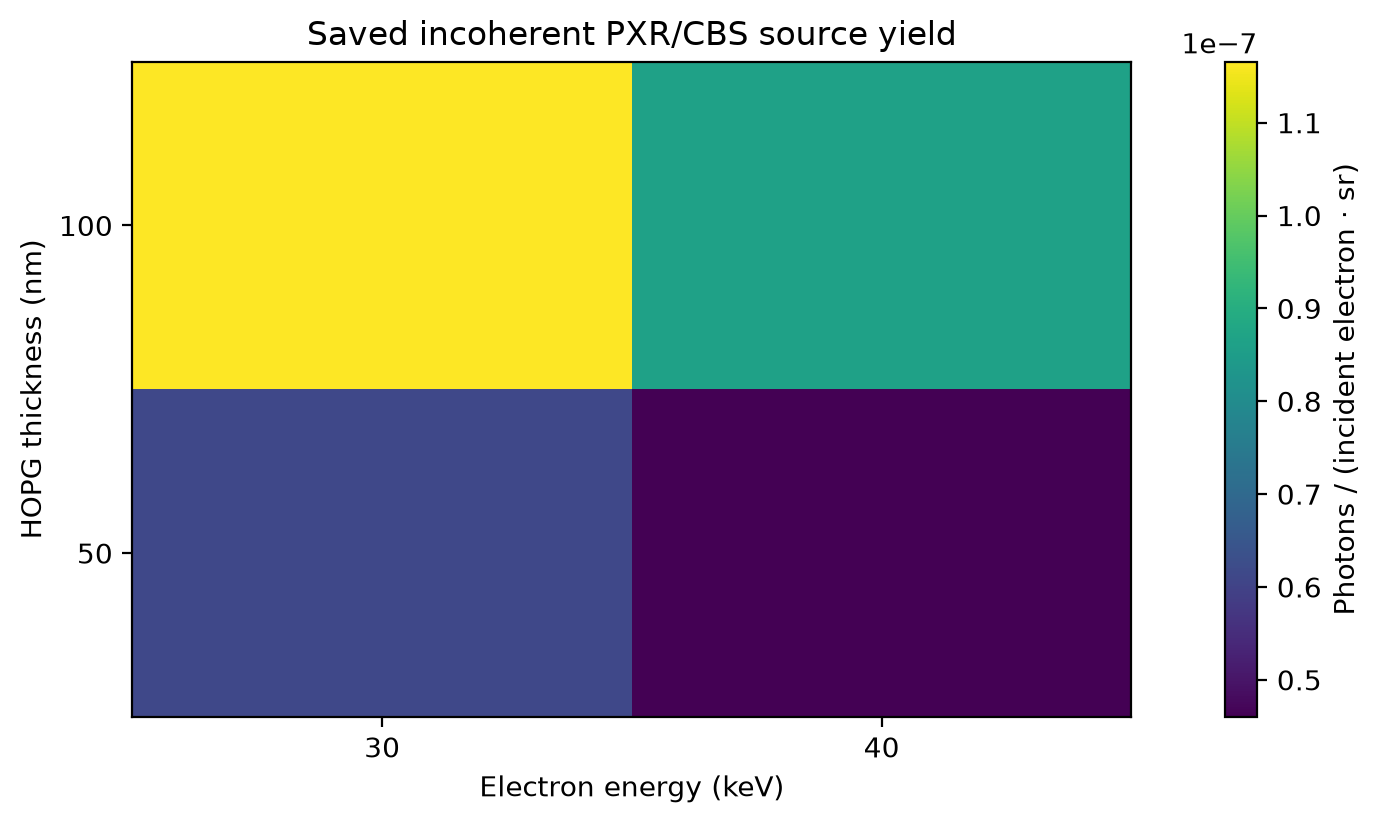

In [ ]:
# Integrate the *saved* incoherent PXR/CBS source spectrum on its native grid.
band_yield = np.full((len(thicknesses_nm), len(energies_keV)), np.nan)
for _record in records(saved_store):
    _case = _record["case"]
    _row = int(np.flatnonzero(np.isclose(thicknesses_nm, _case["thickness_ang"] / 10))[0])
    _col = int(np.flatnonzero(np.isclose(energies_keV, _case["E0_keV"]))[0])
    band_yield[_row, _col] = np.trapezoid(_record["spec"], _record["E_grid"])
assert np.isfinite(band_yield).all()

fig, _ax = plt.subplots(figsize=(6.8, 4), layout="constrained")
_heatmap = _ax.pcolormesh(energies_keV, thicknesses_nm, band_yield, shading="nearest")
_ax.set(
    title="Saved incoherent PXR/CBS source yield",
    xlabel="Electron energy (keV)",
    ylabel="HOPG thickness (nm)",
    xticks=energies_keV,
    yticks=thicknesses_nm,
)
fig.colorbar(_heatmap, ax=_ax, label="Photons / (incident electron · sr)")
fig  # noqa: B018 - captured by marimo

## Reuse this for a larger study

`select_results` filters on **stored case fields** such as `E0_keV` and
`thickness_ang`, not on input quantity objects; the legacy record stores
angles in degrees, thickness in ångström and energy in keV.
`summary_table` uses `Settings()` for read-time response choices and
returns photon **rates**, while the figure integrates the raw, unscaled
source density (not pixel counts). The 64 histories and one reflection
family here are for workflow demonstration, not converged predictions.

A fixed seed makes case identity and results reproducible for identical
software, datasets and execution settings; changing physics, numerics or
axes should use a separate checkpoint root. If interrupted, rerun the same
`run_sweep(cases, {}, checkpoint_dir=..., resume=True)` command with that
root to pick up unfinished cases. A temporary directory disappears when
this notebook closes, so use a real path for cross-session persistence.

For the equivalent **named profile / CLI** workflow, see
[Configure and inspect a campaign](https://pyrite.readthedocs.io/en/latest/guides/configuration-cookbook.html)
and [Checkpoint layout](https://pyrite.readthedocs.io/en/latest/reference/results-and-apps.html).

## Continue learning

Compare with [Parameter sweeps](08-parameter-sweeps.ipynb), then read
[Working with results](../../guides/working-with-results.md) and the
[CLI configuration guide](../../guides/configuration-cookbook.md).

{download}`Download canonical Marimo notebook <../18-persisted-parameter-studies.py>`